In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

print("All Libraries Imported Successfully!")


All Libraries Imported Successfully!


In [5]:

import pandas as pd
from pathlib import Path

try:
    from google.colab import files
    uploaded = files.upload()
    csv_file = next(iter(uploaded.keys()))
except ImportError:
    csv_file = "heart_disease_uci.csv"

df = pd.read_csv(csv_file)

print("Dataset Loaded Successfully!")
print(df.head())

print("\nDataset Shape:", df.shape)


Saving heart_disease_uci.csv to heart_disease_uci.csv
Dataset Loaded Successfully!
   id  age     sex    dataset               cp  trestbps   chol    fbs  \
0   1   63    Male  Cleveland   typical angina     145.0  233.0   True   
1   2   67    Male  Cleveland     asymptomatic     160.0  286.0  False   
2   3   67    Male  Cleveland     asymptomatic     120.0  229.0  False   
3   4   37    Male  Cleveland      non-anginal     130.0  250.0  False   
4   5   41  Female  Cleveland  atypical angina     130.0  204.0  False   

          restecg  thalch  exang  oldpeak        slope   ca  \
0  lv hypertrophy   150.0  False      2.3  downsloping  0.0   
1  lv hypertrophy   108.0   True      1.5         flat  3.0   
2  lv hypertrophy   129.0   True      2.6         flat  2.0   
3          normal   187.0  False      3.5  downsloping  0.0   
4  lv hypertrophy   172.0  False      1.4    upsloping  0.0   

                thal  num  
0       fixed defect    0  
1             normal    2  
2  revers

In [6]:

print("Dataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    object 
 3   dataset   920 non-null    object 
 4   cp        920 non-null    object 
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    object 
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    object 
 13  ca        309 non-null    float64
 14  thal      434 non-null    object 
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(8)
memory usage: 115.1+ KB
None

Statistical Summary:
               id         age    trestbps        chol      thalch     oldpeak  \


In [7]:

print("Duplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("\nDataset Shape After Cleaning:", df.shape)

print("Data Cleaning Completed!")


Duplicate Rows: 0

Dataset Shape After Cleaning: (920, 16)
Data Cleaning Completed!


In [8]:

df['target'] = (df['num'] > 0).astype(int)

print("Target Distribution:")
print(df['target'].value_counts())

print("\n0 = No Heart Disease")
print("1 = Heart Disease")


Target Distribution:
target
1    509
0    411
Name: count, dtype: int64

0 = No Heart Disease
1 = Heart Disease


In [9]:

X = df.drop(
    columns=['id', 'dataset', 'num', 'target']
)

y = df['target']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)


Features:
   age     sex               cp  trestbps   chol    fbs         restecg  \
0   63    Male   typical angina     145.0  233.0   True  lv hypertrophy   
1   67    Male     asymptomatic     160.0  286.0  False  lv hypertrophy   
2   67    Male     asymptomatic     120.0  229.0  False  lv hypertrophy   
3   37    Male      non-anginal     130.0  250.0  False          normal   
4   41  Female  atypical angina     130.0  204.0  False  lv hypertrophy   

   thalch  exang  oldpeak        slope   ca               thal  
0   150.0  False      2.3  downsloping  0.0       fixed defect  
1   108.0   True      1.5         flat  3.0             normal  
2   129.0   True      2.6         flat  2.0  reversable defect  
3   187.0  False      3.5  downsloping  0.0             normal  
4   172.0  False      1.4    upsloping  0.0             normal  

Target:
0    0
1    1
2    1
3    0
4    0
Name: target, dtype: int64

Feature Shape: (920, 13)
Target Shape: (920,)


In [10]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Train Test Split Completed!")


Training Data: (736, 13)
Testing Data: (184, 13)
Train Test Split Completed!


In [11]:

numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

def create_preprocessor():

    numeric_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ])

    return ColumnTransformer([
        ('num', numeric_pipeline, numeric_features),
        ('cat', categorical_pipeline, categorical_features)
    ])

print("Preprocessing Pipeline Created!")


Preprocessing Pipeline Created!


In [12]:

logistic_model = Pipeline([
    ('preprocessor', create_preprocessor()),
    ('classifier', LogisticRegression(
        max_iter=2000,
        class_weight='balanced'
    ))
])

tree_model = Pipeline([
    ('preprocessor', create_preprocessor()),
    ('classifier', DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=5,
        random_state=42,
        class_weight='balanced'
    ))
])

print("Both ML Models Created Successfully!")


Both ML Models Created Successfully!


In [13]:

logistic_model.fit(X_train, y_train)

tree_model.fit(X_train, y_train)

print("Logistic Regression Training Completed!")
print("Decision Tree Training Completed!")


Logistic Regression Training Completed!
Decision Tree Training Completed!


In [14]:

y_pred_lr = logistic_model.predict(X_test)
y_pred_dt = tree_model.predict(X_test)

y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]
y_prob_dt = tree_model.predict_proba(X_test)[:, 1]

print("Predictions Completed!")

print("\nLogistic Regression:")
print(y_pred_lr[:10])

print("\nDecision Tree:")
print(y_pred_dt[:10])


Predictions Completed!

Logistic Regression:
[0 1 1 1 0 1 1 1 0 0]

Decision Tree:
[0 1 1 1 0 1 1 1 0 1]


In [15]:

models = {
    "Logistic Regression": (y_pred_lr, y_prob_lr),
    "Decision Tree": (y_pred_dt, y_prob_dt)
}

results = []

for name, (pred, prob) in models.items():

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(
            y_test, pred, zero_division=0
        ),
        'Recall': recall_score(
            y_test, pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))


                 Model  Accuracy  Precision  Recall  ROC-AUC
0  Logistic Regression    0.8315     0.8381  0.8627   0.9041
1        Decision Tree    0.8152     0.8400  0.8235   0.8584


In [16]:

print("LOGISTIC REGRESSION REPORT")

print(classification_report(
    y_test,
    y_pred_lr,
    target_names=['No Disease', 'Disease'],
    zero_division=0
))

print("\nDECISION TREE REPORT")

print(classification_report(
    y_test,
    y_pred_dt,
    target_names=['No Disease', 'Disease'],
    zero_division=0
))


LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

  No Disease       0.82      0.79      0.81        82
     Disease       0.84      0.86      0.85       102

    accuracy                           0.83       184
   macro avg       0.83      0.83      0.83       184
weighted avg       0.83      0.83      0.83       184


DECISION TREE REPORT
              precision    recall  f1-score   support

  No Disease       0.79      0.80      0.80        82
     Disease       0.84      0.82      0.83       102

    accuracy                           0.82       184
   macro avg       0.81      0.81      0.81       184
weighted avg       0.82      0.82      0.82       184



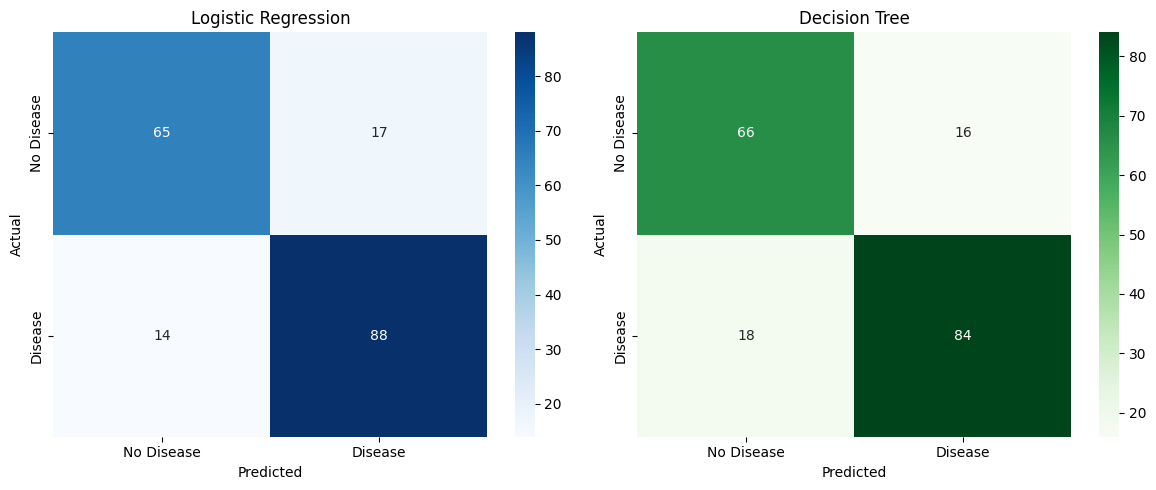

In [17]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_dt = confusion_matrix(y_test, y_pred_dt)

sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Disease', 'Disease'],
    yticklabels=['No Disease', 'Disease'],
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    cm_dt,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['No Disease', 'Disease'],
    yticklabels=['No Disease', 'Disease'],
    ax=axes[1]
)

axes[1].set_title("Decision Tree")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


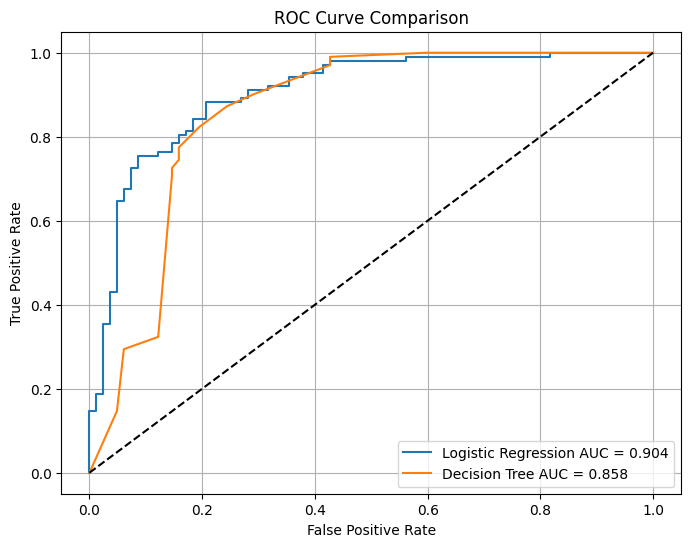

In [18]:

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)

auc_lr = roc_auc_score(y_test, y_prob_lr)
auc_dt = roc_auc_score(y_test, y_prob_dt)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_lr,
    tpr_lr,
    label=f'Logistic Regression AUC = {auc_lr:.3f}'
)

plt.plot(
    fpr_dt,
    tpr_dt,
    label=f'Decision Tree AUC = {auc_dt:.3f}'
)

plt.plot([0, 1], [0, 1], 'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.grid()
plt.show()


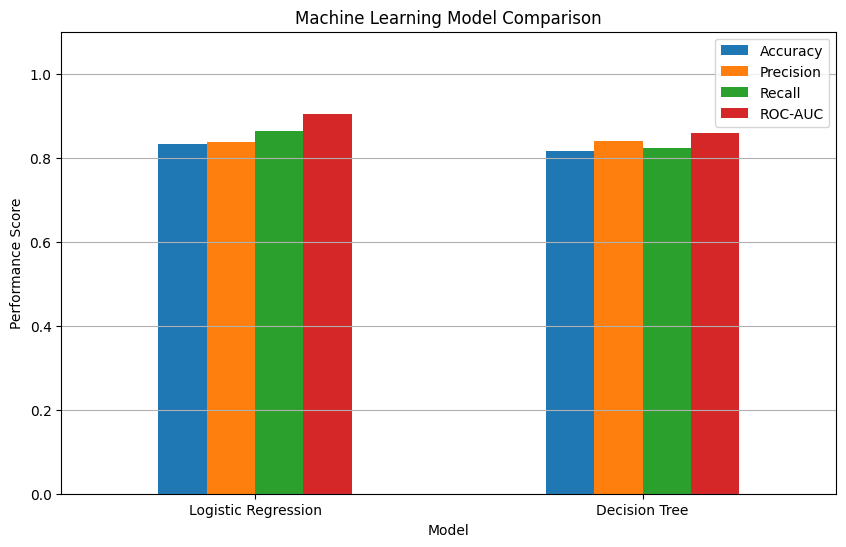

In [19]:

results_df.set_index('Model').plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Performance Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.show()


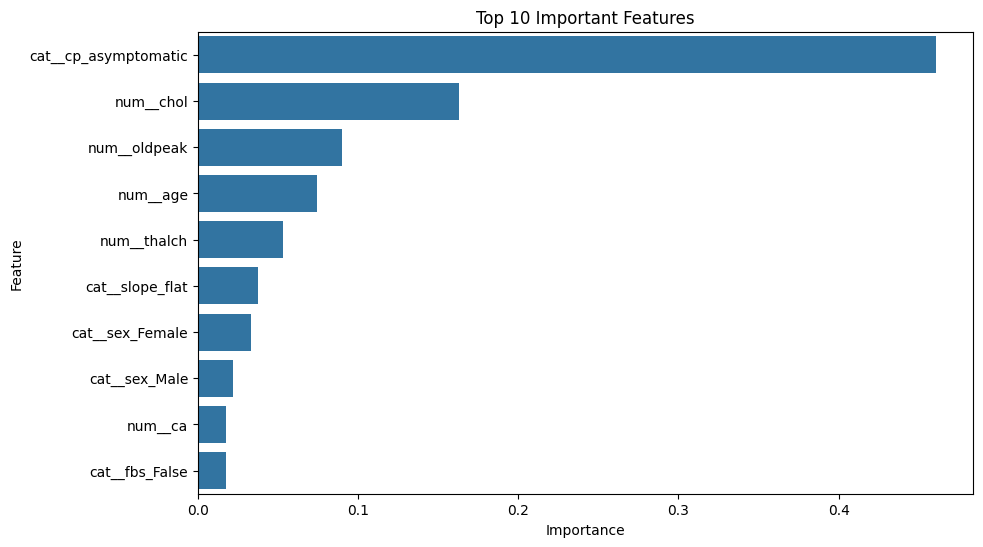

                 Feature  Importance
8   cat__cp_asymptomatic    0.460905
2              num__chol    0.163216
4           num__oldpeak    0.089931
0               num__age    0.074434
3            num__thalch    0.052871
20       cat__slope_flat    0.037386
6        cat__sex_Female    0.033177
7          cat__sex_Male    0.022039
5                num__ca    0.017745
12        cat__fbs_False    0.017655


In [20]:

feature_names = tree_model.named_steps[
    'preprocessor'
].get_feature_names_out()

importance = tree_model.named_steps[
    'classifier'
].feature_importances_

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Important Features")
plt.show()

print(importance_df)


In [23]:
import joblib

print("Joblib Imported Successfully!")

Joblib Imported Successfully!


In [24]:
joblib.dump(
    logistic_model,
    'heart_disease_logistic_model.pkl'
)

joblib.dump(
    tree_model,
    'heart_disease_decision_tree_model.pkl'
)

print("Both Models Saved Successfully!")

Both Models Saved Successfully!


In [25]:

print("======================================")
print(" HEART DISEASE PREDICTION PROJECT")
print("======================================")

print("Dataset Records:", len(df))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nModel Performance:")
print(results_df.round(4).to_string(index=False))

best_model = results_df.loc[
    results_df['ROC-AUC'].idxmax()
]

print("\nBest Model Based on ROC-AUC:")
print(best_model['Model'])

print("\nPROJECT COMPLETED SUCCESSFULLY!")
print("======================================")


 HEART DISEASE PREDICTION PROJECT
Dataset Records: 920
Training Records: 736
Testing Records: 184

Model Performance:
              Model  Accuracy  Precision  Recall  ROC-AUC
Logistic Regression    0.8315     0.8381  0.8627   0.9041
      Decision Tree    0.8152     0.8400  0.8235   0.8584

Best Model Based on ROC-AUC:
Logistic Regression

PROJECT COMPLETED SUCCESSFULLY!


In [26]:

results_df.to_csv(
    'heart_disease_model_results.csv',
    index=False
)

print("Results CSV Saved Successfully!")


Results CSV Saved Successfully!
